# Ripple - exploratory data analysis

Two parts:

* **A. Real data** collected so far: LOT rotations from the OpenSky Zenodo flight list (Nov 2022),
  METAR/TAF archives, and the live OpenSky collector.
* **B. Synthetic network**. This is the simulator the models are developed on until scheduled times
  arrive (see `docs/data_sources.md`). Part B checks that it looks like a hub carrier, using the
  real rotation structure from part A.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from ripple import config
from ripple.data import sources
from ripple.data.build import load
from ripple.data.schema import add_labels
from ripple.data.network import add_rotations, connections, realised_miss
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## A1. Real LOT rotations - OpenSky flight list, November 2022

In [2]:
z = sources.load_zenodo_lot(ROOT / "data/raw/zenodo/flightlist_20221101_20221130.csv.gz")
z = z.dropna(subset=["icao24"]).sort_values(["icao24", "firstseen"])
print(f"{len(z):,} LOT legs, {z.icao24.nunique()} airframes, "
      f"{(z.origin.eq('EPWA') | z.destination.eq('EPWA')).mean():.1%} touch WAW")
z["date"] = z.firstseen.dt.date
legs = z.groupby(["icao24", "date"]).size()
by_type = z.groupby("typecode").apply(lambda g: g.groupby(["icao24", "date"]).size().mean())
print("mean legs per active aircraft-day by type:"); print(by_type.round(2).sort_values())

7,456 LOT legs, 71 airframes, 96.5% touch WAW
mean legs per active aircraft-day by type:
typecode
B788    1.43
B789    1.62
B738    2.79
B38M    3.52
E190    4.97
E195    5.03
E170    5.71
E75S    5.74
DH8D    5.86
dtype: float64


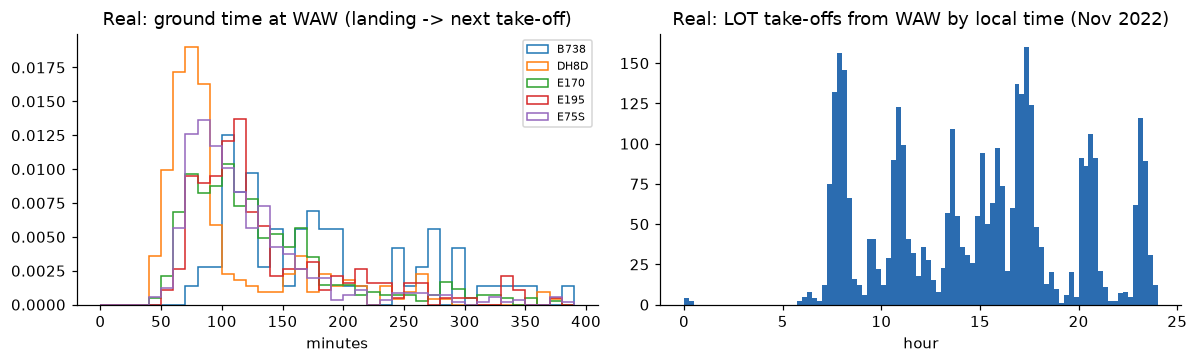

typecode
B38M    194.0
B738    181.0
B788    262.0
B789    319.0
DH8D     83.0
E170    118.0
E190    114.0
E195    116.0
E75S    107.0
Name: ground_min, dtype: float64


In [3]:
# Ground time at WAW: landing at WAW -> next take-off of the same airframe from WAW
z["next_takeoff"] = z.groupby("icao24").firstseen.shift(-1)
z["next_origin"] = z.groupby("icao24").origin.shift(-1)
g = z[(z.destination == "EPWA") & (z.next_origin == "EPWA")].copy()
g["ground_min"] = (g.next_takeoff - g.lastseen).dt.total_seconds() / 60
g = g[g.ground_min.between(0, 600)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for t, gg in g.groupby("typecode"):
    if len(gg) > 60:
        ax[0].hist(gg.ground_min, bins=np.arange(0, 400, 10), histtype="step", label=t, density=True)
ax[0].set(title="Real: ground time at WAW (landing -> next take-off)", xlabel="minutes"); ax[0].legend(fontsize=7)
dep = z[z.origin == "EPWA"]
h = dep.firstseen.dt.tz_convert("Europe/Warsaw")
ax[1].hist(h.dt.hour + h.dt.minute / 60, bins=np.arange(0, 24.01, 0.25), color="#2b6cb0")
ax[1].set(title="Real: LOT take-offs from WAW by local time (Nov 2022)", xlabel="hour")
plt.tight_layout(); plt.savefig(FIG / "real_rotations.png"); plt.show()
print(g.groupby("typecode").ground_min.median().round(0))

Real WAW departures come in clear **banks**. Wide-bodies sit on the ground for 2 h or more;
E-jets and Q400s often turn in 35-60 minutes, which leaves little room to absorb a late inbound.
Note that these are *airborne* times (take-off/landing), not gate times. Taxi time is included in
the ground time.

## A2. Weather archives (real)

In [4]:
m = sources.load_metar()
print(f"METAR reports: {len(m):,} from {m.time.min()} to {m.time.max()}, {m.icao.nunique()} stations")
adv = m.groupby("icao").severity.apply(lambda s: (s > 0.3).mean()).sort_values(ascending=False)
print("share of reports with severity > 0.3 (top 10):"); print(adv.head(10).round(3))
t = sources.load_taf(); print(f"TAF hourly forecast rows: {len(t):,} (archive started 2026-10-26)")

METAR reports: 10,105 from 2026-10-23 00:00:00+00:00 to 2026-10-26 21:30:00+00:00, 57 stations
share of reports with severity > 0.3 (top 10):
icao
LROP    0.428
LUKK    0.251
EYVI    0.209
LFPG    0.160
EHAM    0.158
RJTT    0.112
EVRA    0.112
ESSA    0.096
EDDL    0.096
EGCC    0.091
Name: severity, dtype: float64


TAF hourly forecast rows: 1,499 (archive started 2026-10-26)


In [5]:
st = sorted((ROOT / "data/raw/opensky_states").glob("*.jsonl"))
n = sum(1 for p in st for _ in open(p))
print(f"OpenSky state rows collected: {n:,} in {len(st)} daily files")
ev = sources.states_to_movements()
print(f"detected LOT take-offs/landings at WAW so far: {len(ev)}")

OpenSky state rows collected: 32 in 1 daily files
detected LOT take-offs/landings at WAW so far: 0


## B. Synthetic network

In [6]:
f, wx, fc = load("synthetic")
f = add_labels(add_rotations(f))
print(f"{len(f):,} legs, {f["tail"].nunique()} tails, {f.sched_dep.dt.date.nunique()} days")
print(f"OTP15 departures {(f.dep_delay <= 15).mean():.1%}, arrivals {(f.arr_delay <= 15).mean():.1%} "
      f"(LOT 2024 arrivals ~77.7% per Cirium)")
causes = [c for c in f if c.startswith("cause_")]
share = (f[causes].sum() / f[causes].sum().sum()).rename(lambda c: c[6:])
print("share of delay minutes by true cause:"); print(share.round(3))

120,664 legs, 77 tails, 366 days
OTP15 departures 70.5%, arrivals 76.6% (LOT 2024 arrivals ~77.7% per Cirium)
share of delay minutes by true cause:
reactionary    0.302
primary        0.301
weather        0.097
atfm           0.105
congestion     0.176
hold           0.019
dtype: float64


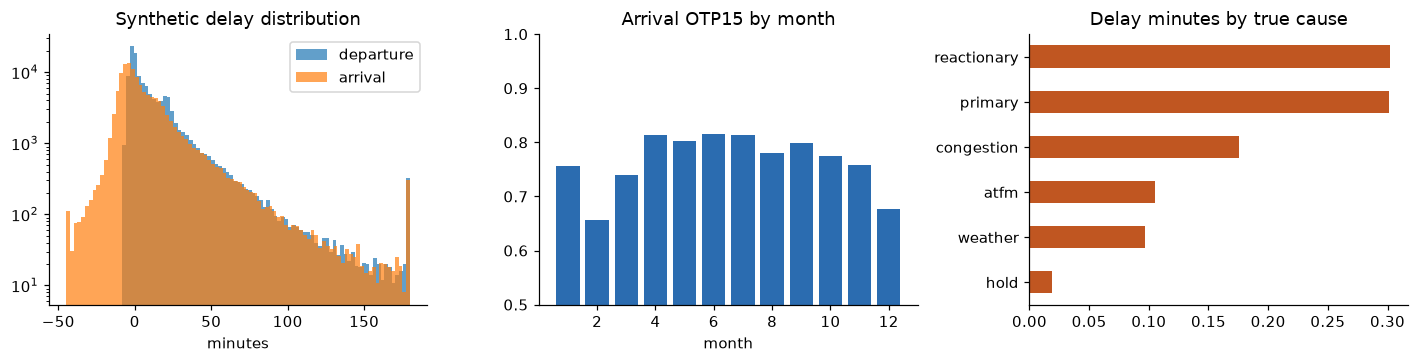

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(f.dep_delay.clip(-15, 180), bins=78, alpha=.7, label="departure")
ax[0].hist(f.arr_delay.clip(-45, 180), bins=90, alpha=.7, label="arrival")
ax[0].set(yscale="log", title="Synthetic delay distribution", xlabel="minutes"); ax[0].legend()
mo = f.groupby(f.sched_dep.dt.month).apply(lambda g: (g.arr_delay <= 15).mean())
ax[1].bar(mo.index, mo.values, color="#2b6cb0"); ax[1].set(ylim=(.5, 1), title="Arrival OTP15 by month", xlabel="month")
share.sort_values().plot.barh(ax=ax[2], color="#c05621"); ax[2].set(title="Delay minutes by true cause")
plt.tight_layout(); plt.savefig(FIG / "synthetic_overview.png"); plt.show()

### Propagation along rotations
For each leg with a known previous leg: the late inbound eats into the scheduled turn slack. The
departure delay should follow `max(0, inbound arrival delay - slack)` (the dashed line).

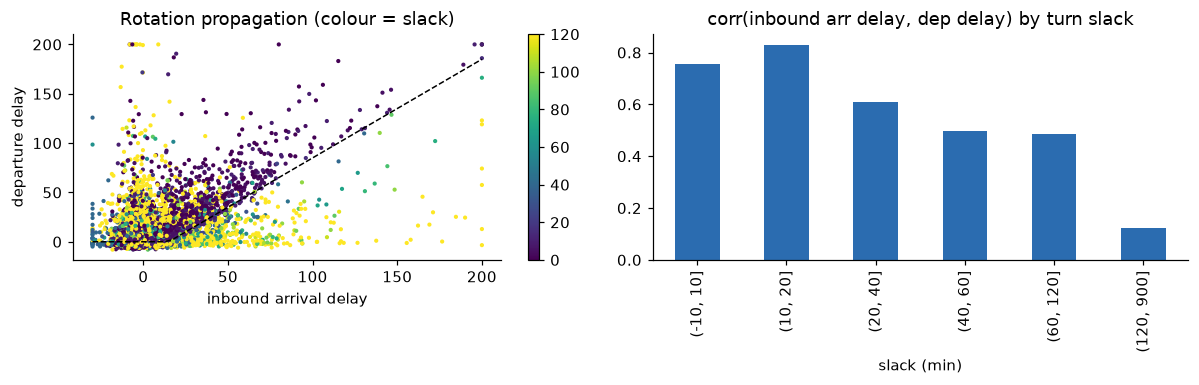

In [8]:
idx = f.set_index("flight_id")
r = f.dropna(subset=["prev_id"]).copy()
r["in_arr_delay"] = idx.loc[r.prev_id.astype(int), "arr_delay"].to_numpy()
r["slack"] = r.turn_buffer - r.ac_type.map({"B789": 110, "B38M": 50, "E195": 40, "E175": 35, "DH8D": 30})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
s = r.sample(8000, random_state=0)
sc = ax[0].scatter(s.in_arr_delay.clip(-30, 200), s.dep_delay.clip(-15, 200), c=s.slack.clip(0, 120), s=3, cmap="viridis")
xx = np.linspace(-30, 200); ax[0].plot(xx, np.maximum(0, xx - 15), "k--", lw=1)
ax[0].set(xlabel="inbound arrival delay", ylabel="departure delay", title="Rotation propagation (colour = slack)")
plt.colorbar(sc, ax=ax[0])
bins = pd.cut(r.slack, [-10, 10, 20, 40, 60, 120, 900])
(r.groupby(bins, observed=True).apply(lambda g: np.corrcoef(g.in_arr_delay, g.dep_delay)[0, 1])
   .plot.bar(ax=ax[1], color="#2b6cb0"))
ax[1].set(title="corr(inbound arr delay, dep delay) by turn slack", xlabel="slack (min)")
plt.tight_layout(); plt.savefig(FIG / "synthetic_propagation.png"); plt.show()

### Connections at WAW

1,479,327 schedule-feasible connections, realised miss rate 4.0%


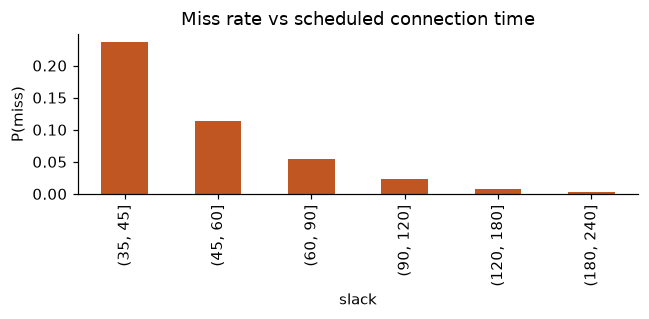

In [9]:
pairs = connections(f)
pairs["miss"] = realised_miss(pairs, f)
print(f"{len(pairs):,} schedule-feasible connections, realised miss rate {pairs.miss.mean():.1%}")
mr = pairs.groupby(pd.cut(pairs.slack, [35, 45, 60, 90, 120, 180, 240]), observed=True).miss.mean()
ax = mr.plot.bar(color="#c05621", figsize=(6, 3)); ax.set(title="Miss rate vs scheduled connection time", ylabel="P(miss)")
plt.tight_layout(); plt.savefig(FIG / "synthetic_connections.png"); plt.show()

### Simulator vs reality: bank structure and ground times

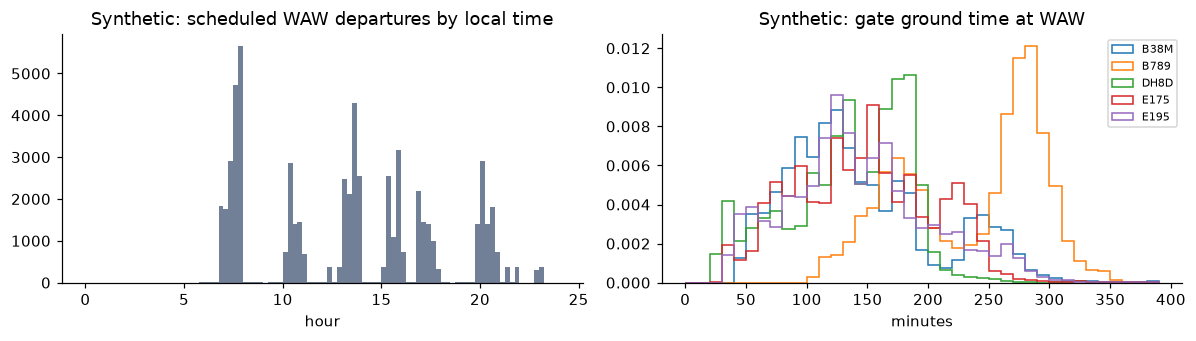

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
sd = f[f.dep_airport == "EPWA"].sched_dep.dt.tz_convert("Europe/Warsaw")
ax[0].hist(sd.dt.hour + sd.dt.minute / 60, bins=np.arange(0, 24.01, .25), color="#718096")
ax[0].set(title="Synthetic: scheduled WAW departures by local time", xlabel="hour")
gs = r[r.dep_airport == "EPWA"]
prev_arr = pd.Series(idx.loc[gs.prev_id.astype(int), "actual_arr"].to_numpy(), index=gs.index)
gs = gs.assign(ground=(gs.actual_dep - prev_arr).dt.total_seconds() / 60)
for t, gg in gs.groupby("ac_type"):
    ax[1].hist(gg.ground.clip(0, 400), bins=np.arange(0, 400, 10), histtype="step", density=True, label=t)
ax[1].set(title="Synthetic: gate ground time at WAW", xlabel="minutes"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "synthetic_vs_real_banks.png"); plt.show()

**Takeaways**

* The real data shows a bank structure and short E-jet turns, and the simulator reproduces both.
  The simulator's turns are gate-to-gate, so they are ~15-25 min shorter than the real
  landing-to-take-off times above.
* Rotation propagation is strong when turn slack is small and fades above ~60 min of slack. This
  is the signal the rotation edges have to carry.
* Connection misses are concentrated in the 35-60 min band.
* The synthetic delay mix is close to LOT's reported punctuality. Reactionary delay is a smaller
  share of minutes than the CODA figure (~40-48%) because our accounting credits a leg to a single
  dominant cause.